In [7]:
x=1

In [8]:
import scanpy as sc
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from multimil.utils import get_sample_representations
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from pprint import pprint

In [9]:
adata = sc.read_h5ad('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scvi/6e49b5e194_adata_both.h5ad')
adata

AnnData object with n_obs × n_vars = 215678 × 30
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels', 'group', 'cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn'
    uns: 'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors

In [10]:
status_palette = {
    'Healthy': '#C2BC00',
    'Mild': '#E59A88',
    'Severe': '#B62A6F'
}

condition_key = 'Status_on_day_collection_summary'
sample_key = 'sample_id'

mean
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9
weighted
0.1
0.2
0.3
0.4
0.5
0.6
0.7
0.8
0.9


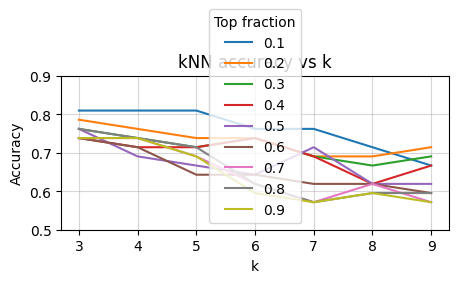

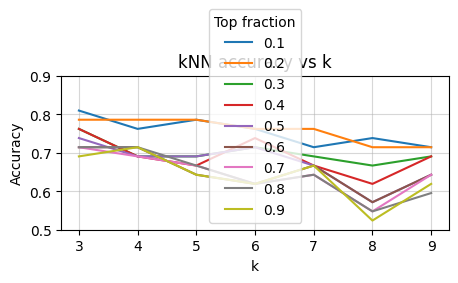

In [12]:
top_fracs = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

for agg in ['mean', 'weighted']:
    print(agg)
    knn_results = []
    for top_frac in top_fracs:
        tag = f'{agg}_top{int(top_frac*100)}'
        print(top_frac)

        # get sample representations
        reps = get_sample_representations(
            adata,
            sample_key=sample_key,
            aggregation=agg,
            cell_attn_key='cell_attn',
            top_fraction=top_frac,
            covs_to_keep=[condition_key]
        )

        # kNN classification
        X = reps.X if isinstance(reps.X, np.ndarray) else reps.X.toarray()
        y = reps.obs[condition_key].values
        le = LabelEncoder()
        y_enc = le.fit_transform(y)
        accs = []
        for k in range(3, 10):
            clf = KNeighborsClassifier(n_neighbors=k)
            clf.fit(X, y_enc)
            y_pred = clf.predict(X)
            acc = accuracy_score(y_enc, y_pred)
            accs.append({'k': k, 'accuracy': acc, 'top_frac': str(top_frac)})
        knn_results.append(pd.DataFrame(accs))

    # plot kNN results for this aggregation
    knn_df = pd.concat(knn_results, ignore_index=True)
    knn_df.to_csv(f'results/knn_{agg}_top_frac_sweep.csv', index=False)
    plt.figure(figsize=(5,2))
    sns.lineplot(data=knn_df, x='k', y='accuracy', hue='top_frac', palette='tab10') # marker='o',
    plt.title(f'kNN accuracy vs k')
    plt.ylabel('Accuracy')
    plt.xlabel('k')
    unique_k = sorted(knn_df['k'].unique())
    plt.xticks(unique_k)
    plt.ylim(0.5, 0.9)
    plt.grid(True, alpha=0.5, zorder=0)
    plt.legend(title='Top fraction')
    plt.savefig(f'figures/knn_{agg}_top_frac_sweep.svg', bbox_inches='tight', dpi=300)